# Data Analysis

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

from securebank.modules.data.raw_data_handler import RawDataHandler

## Exploring Data

In [2]:
# Initialize RawDataHandler
handler = RawDataHandler(storage_path="../storage", save_path="../storage")

# Extract raw data
customer_info, transaction_info, fraud_info = handler.extract("customer_release.csv", "transactions_release.parquet", "fraud_release.json")

# Transform data
cleaned_data = handler.transform(customer_info, transaction_info, fraud_info)
cleaned_data = handler.convert_dates(cleaned_data)

# Describe cleaned data
description = handler.describe(cleaned_data)
description

{'Number of records': 1482872,
 'Number of columns': 32,
 'Feature names': ['trans_num',
  'index_x',
  'trans_date_trans_time',
  'cc_num',
  'unix_time',
  'merchant',
  'category',
  'amt',
  'merch_lat',
  'merch_long',
  'is_fraud',
  'index_y',
  'first',
  'last',
  'sex',
  'street',
  'city',
  'state',
  'zip',
  'lat',
  'long',
  'city_pop',
  'job',
  'dob',
  'day_of_week',
  'hour',
  'minute',
  'seconds',
  'day_date',
  'month_date',
  'month_num',
  'year_date'],
 'Missing values count': 0,
 'Memory usage': '1457.92 MB',
 'Fraud prevalence': '0.0044',
 'Min Transaction Time': '2019-01-01 00:00:18',
 'Max Transaction Time': '2020-12-31 23:59:34'}

In [3]:
cleaned_data

,trans_num,index_x,trans_date_trans_time,cc_num,unix_time,merchant,category,amt,merch_lat,merch_long,...,job,dob,day_of_week,hour,minute,seconds,day_date,month_date,month_num,year_date
0,00000ecad06b03d3a8d34b4e30b5ce3b,852047,2019-12-15 20:23:10,6593250708747804,1.355603e+09,fraud_Yost-Rogahn,personal_care,66.01,26.880712,-79.277659,...,PARAMEDIC,04/01/1977,Sunday,20,23,10,15,December,12,2019
1,000014ca3f6921fe6793f88fe494f39d,6766,2019-01-05 11:12:15,4302480582202074,1.325762e+09,fraud_Padberg-Welch,grocery_pos,91.73,42.533807,-86.610405,...,Historic buildings inspector/conservation officer,"May 25, 1995",Saturday,11,12,15,5,January,1,2019
2,00001ded488fddab97677128e5034d39,889067,2019-12-23 19:06:40,3583635130604947,1.356290e+09,fraud_Zboncak Ltd,food_dining,48.03,39.594014,-74.548268,...,STRUCTURAL ENGINEER,01/01/1985,Monday,19,6,40,23,December,12,2019
4,0000258ae973a6199fca79d94947672f,510332,2019-08-09 16:56:33,30273037698427,1.344531e+09,"fraud_Lockman, West and Runte",grocery_pos,50.56,36.495068,-92.304638,...,CAREERS INFORMATION OFFICER,"Jun 13, 2000",Friday,16,56,33,9,August,8,2019
5,0000307898b3352b5a0d66015d362794,106420,2019-03-02 20:44:08,30560609640617,1.330721e+09,fraud_Schuppe LLC,entertainment,102.51,39.852704,-91.177088,...,TOWN PLANNER,13-Feb-1966,Saturday,20,44,8,2,March,3,2019
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1647536,ffffaf35c5a6eabb3788431eba975c60,354480,2019-06-15 09:47:07,502038091380,1.339754e+09,fraud_Hermann-Gaylord,misc_pos,29.62,36.868303,-93.379920,...,"ENGINEER, AGRICULTURAL",18/03/1980,Saturday,9,47,7,15,June,6,2019
1647537,ffffb8e3e4a2c7ea753eeec1601d34d6,860434,2019-12-17 11:12:29,4777065439639721,1.355743e+09,"fraud_Stokes, Christiansen and Sipes",grocery_net,50.25,40.537162,-75.785289,...,Oceanographer,24-Apr-1987,Tuesday,11,12,29,17,December,12,2019
1647539,ffffc1df97a828ae4c69359c9f05daab,1757338,2020-12-11 00:30:22,180065479077096,1.386722e+09,"fraud_Langosh, Wintheiser and Hyatt",food_dining,111.81,40.271192,-77.625222,...,CLINICAL RESEARCH ASSOCIATE,15-Feb-1964,Friday,0,30,22,11,December,12,2020
1647540,ffffdd4a4136ac60e6a12e15c50be29d,892293,2019-12-24 16:00:26,4599735407877245080,1.356365e+09,fraud_Waelchi Inc,kids_pets,111.00,35.480712,-90.132221,...,Geochemist,"Dec 30, 1964",Tuesday,16,0,26,24,December,12,2019


In [16]:
if cleaned_data['cc_num'].isin(['38859492057661']).any():
    print(True)
else:
    print(False)

False


In [5]:
# Check missing values per column
print(cleaned_data.isnull().sum())

trans_num                0
index_x                  0
trans_date_trans_time    0
cc_num                   0
unix_time                0
merchant                 0
category                 0
amt                      0
merch_lat                0
merch_long               0
is_fraud                 0
index_y                  0
first                    0
last                     0
sex                      0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
day_of_week              0
hour                     0
minute                   0
seconds                  0
day_date                 0
month_date               0
month_num                0
year_date                0
dtype: int64


In [6]:
# Count the number of 1.0 values in the is_fraud column
fraud_count = cleaned_data['is_fraud'].value_counts().get(1.0, 0)

print(f"There are {fraud_count} transactions labeled as fraudulent.")

There are 6496 transactions labeled as fraudulent.


In [7]:
unique_categories = cleaned_data['category'].unique()
print(unique_categories)

['personal_care' 'grocery_pos' 'food_dining' 'entertainment' 'unknown'
 'grocery_net' 'health_fitness' 'shopping_net' 'misc_pos' 'home'
 'shopping_pos' 'gas_transport' 'kids_pets' 'misc_net' 'travel']


In [8]:
# Filter rows where the category is 'unknown'
unknown_df = cleaned_data[cleaned_data['category'] == 'Unknown']

# Check the count of fraudulent vs. non-fraudulent transactions in these rows
fraud_counts = unknown_df['is_fraud'].value_counts()
print(fraud_counts)

# Alternatively, you can see the proportion of fraud for 'unknown' compared to other categories
fraud_rate_by_category = cleaned_data.groupby('category')['is_fraud'].mean()
print(fraud_rate_by_category)

Series([], Name: count, dtype: int64)
category
entertainment     0.001937
food_dining       0.001471
gas_transport     0.003369
grocery_net       0.002388
grocery_pos       0.010345
health_fitness    0.001477
home              0.001569
kids_pets         0.001663
misc_net          0.010419
misc_pos          0.002442
personal_care     0.002066
shopping_net      0.012707
shopping_pos      0.005068
travel            0.002457
unknown           0.004715
Name: is_fraud, dtype: float64


## Distribution of Transaction by Hour

Show fraud and non-fraudulent occurrences vary by hour 0-23

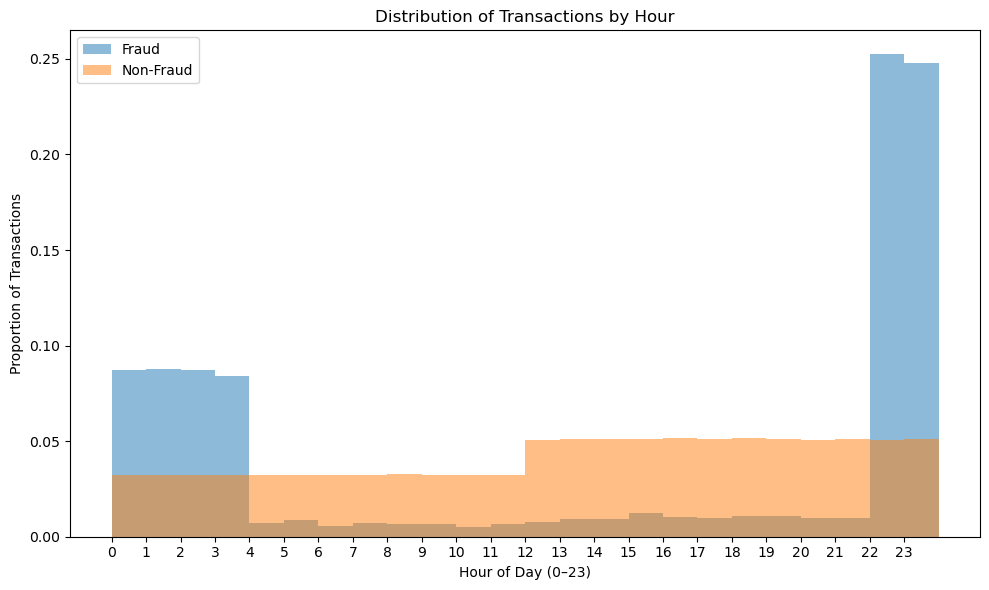

In [9]:
# Separate DataFrame into fraud and non-fraud subsets
df_fraud = cleaned_data[cleaned_data['is_fraud'] == 1]
df_non_fraud = cleaned_data[cleaned_data['is_fraud'] == 0]

plt.figure(figsize=(10, 6))

# Plot histogram fraudulent transactions
plt.hist(df_fraud['hour'], bins=range(0, 25), alpha=0.5, label='Fraud', density=True)

# Plot histogram non-fraudulent transactions
plt.hist(df_non_fraud['hour'], bins=range(0, 25), alpha=0.5, label='Non-Fraud', density=True)

# Labeling and legend
plt.title('Distribution of Transactions by Hour')
plt.xlabel('Hour of Day (0–23)')
plt.ylabel('Proportion of Transactions')
plt.xticks(range(0, 24))
plt.legend()
plt.tight_layout()
plt.show()

## Distribution for Day of Week and Month

Shows fraudulent and non-fraudulent occurrences vary by day of the week and month.

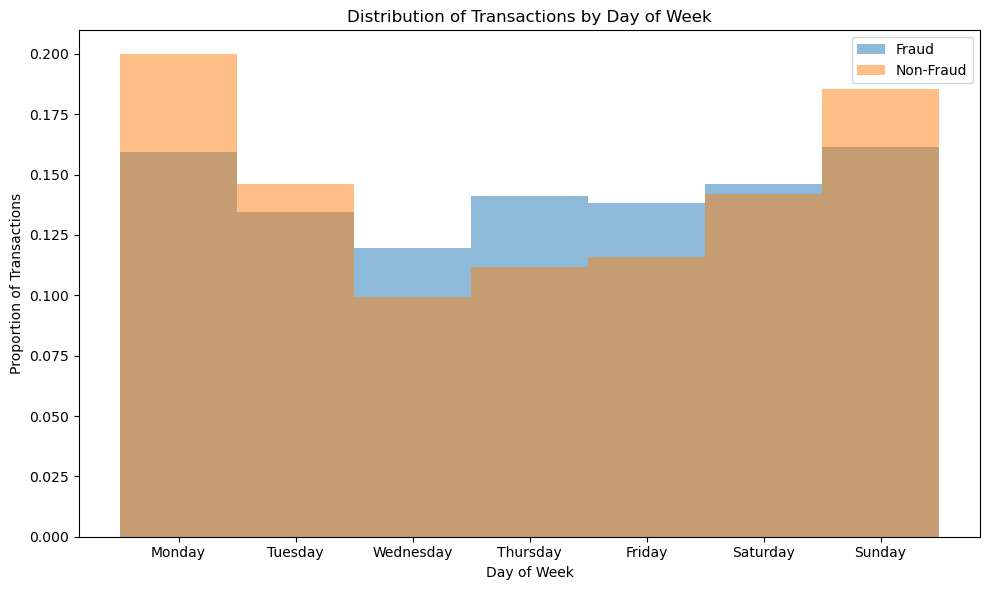

In [10]:
# Ensure day_of_week column is ordered categorical variable
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
cleaned_data['day_of_week'] = pd.Categorical(cleaned_data['day_of_week'], categories=day_order, ordered=True)

# Map day names to numeric values
day_map = {day: i for i, day in enumerate(day_order)}
cleaned_data['day_num'] = cleaned_data['day_of_week'].map(day_map)

# Separate DataFrame into fraudulent and non-fraudulent
df_fraud = cleaned_data[cleaned_data['is_fraud'] == 1]
df_non_fraud = cleaned_data[cleaned_data['is_fraud'] == 0]

plt.figure(figsize=(10, 6))

# Define bins so each day is centered in its bin
bins = np.arange(-0.5, 7.5, 1)

# Plot histogram fraudulent transactions
plt.hist(df_fraud['day_num'].dropna(), bins=bins, alpha=0.5, label='Fraud', density=True)

# Plot histogram non-fraudulent transactions
plt.hist(df_non_fraud['day_num'].dropna(), bins=bins, alpha=0.5, label='Non-Fraud', density=True)

# Labeling and legend
plt.title('Distribution of Transactions by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Proportion of Transactions')
plt.xticks(ticks=range(7), labels=day_order)
plt.legend()
plt.tight_layout()
plt.show()

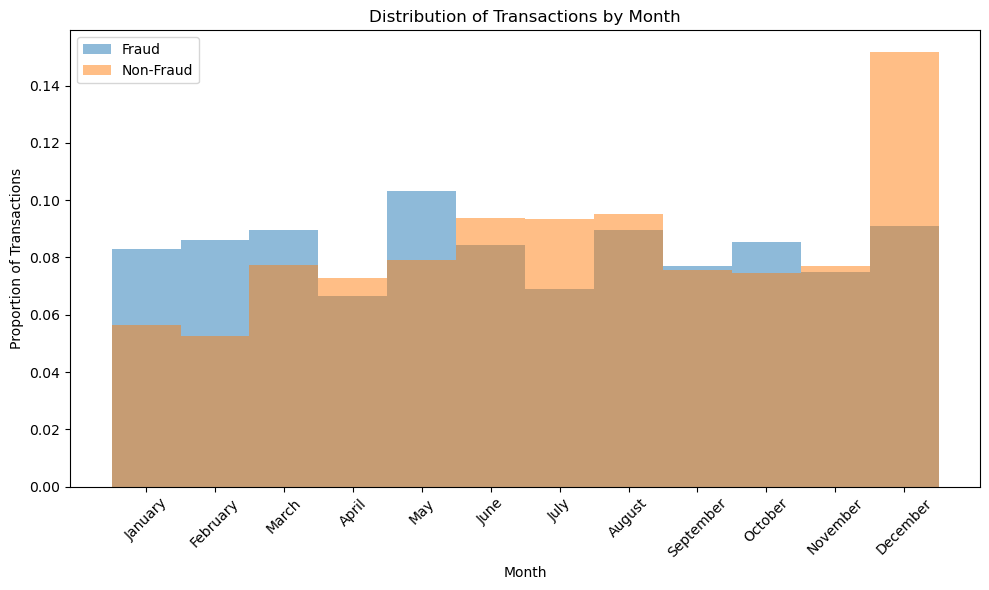

In [11]:
# Ensure month_date column is an ordered categorical variable
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
cleaned_data['month_date'] = pd.Categorical(cleaned_data['month_date'], categories=month_order, ordered=True)

# Map month names to numeric values
month_map = {month: i for i, month in enumerate(month_order)}
cleaned_data['month_num'] = cleaned_data['month_date'].map(month_map)

# Separate DataFrame into fraudulent and non-fraudulent subsets
df_fraud = cleaned_data[cleaned_data['is_fraud'] == 1]
df_non_fraud = cleaned_data[cleaned_data['is_fraud'] == 0]

plt.figure(figsize=(10, 6))

# Define bins so that each month is centered in its bin
bins = np.arange(-0.5, 12.5, 1)

# Plot histogram for fraudulent transactions
plt.hist(df_fraud['month_num'].dropna(), bins=bins, alpha=0.5, label='Fraud', density=True)

# Plot histogram for non-fraudulent transactions
plt.hist(df_non_fraud['month_num'].dropna(), bins=bins, alpha=0.5, label='Non-Fraud', density=True)

plt.title('Distribution of Transactions by Month')
plt.xlabel('Month')
plt.ylabel('Proportion of Transactions')
plt.xticks(ticks=range(12), labels=month_order, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## Fraudulent Transaction Occurring in Quick Succession

Show fraudulent transactions often happen in rapid bursts

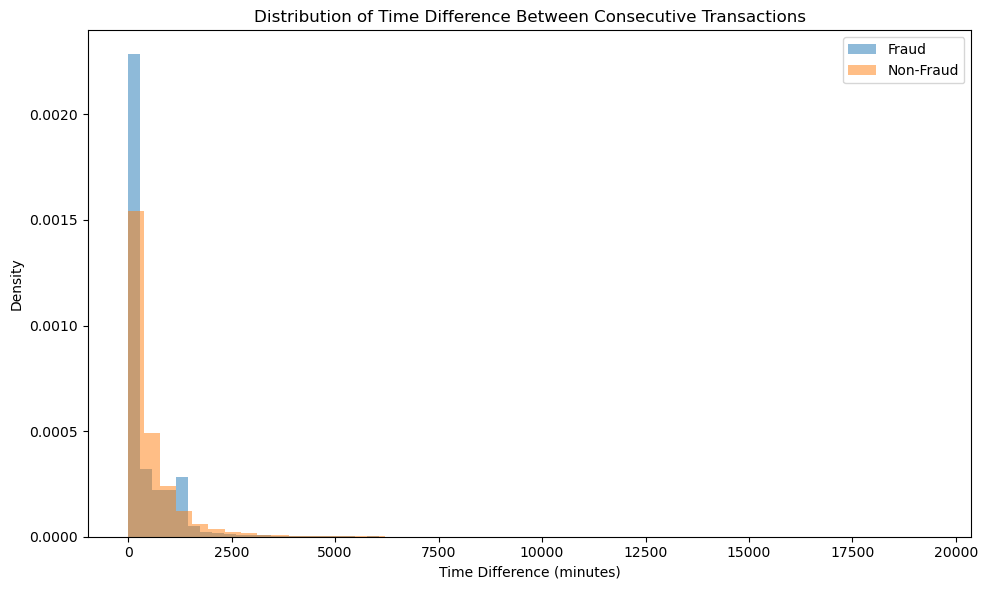

In [12]:
# Sort by customer and transaction time
df =cleaned_data.sort_values(by=['cc_num', 'trans_date_trans_time'])

# Compute time difference (in minutes, for example) between consecutive transactions per customer
df['time_diff'] = df.groupby('cc_num')['trans_date_trans_time'].diff().dt.total_seconds() / 60.0

# Create subsets
df_fraud = df[df['is_fraud'] == 1].copy()
df_non_fraud = df[df['is_fraud'] == 0].copy()

# Plot histograms or boxplots comparing time_diff
plt.figure(figsize=(10,6))

plt.hist(df_fraud['time_diff'].dropna(), bins=50, alpha=0.5, label='Fraud', density=True)

plt.hist(df_non_fraud['time_diff'].dropna(), bins=50, alpha=0.5, label='Non-Fraud', density=True)

plt.title('Distribution of Time Difference Between Consecutive Transactions')
plt.xlabel('Time Difference (minutes)')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

## Purchase Category Plotted Mean and Standard AMT

For each purchase `category`, we calculated the mean and standard deviation of transaction amount for fraudulent and non-fraudulent transactions. We used the values to plot the probability distribution function over a histogram of the actual transaction amount distribution to see how well the data actually fit a normal distribution.

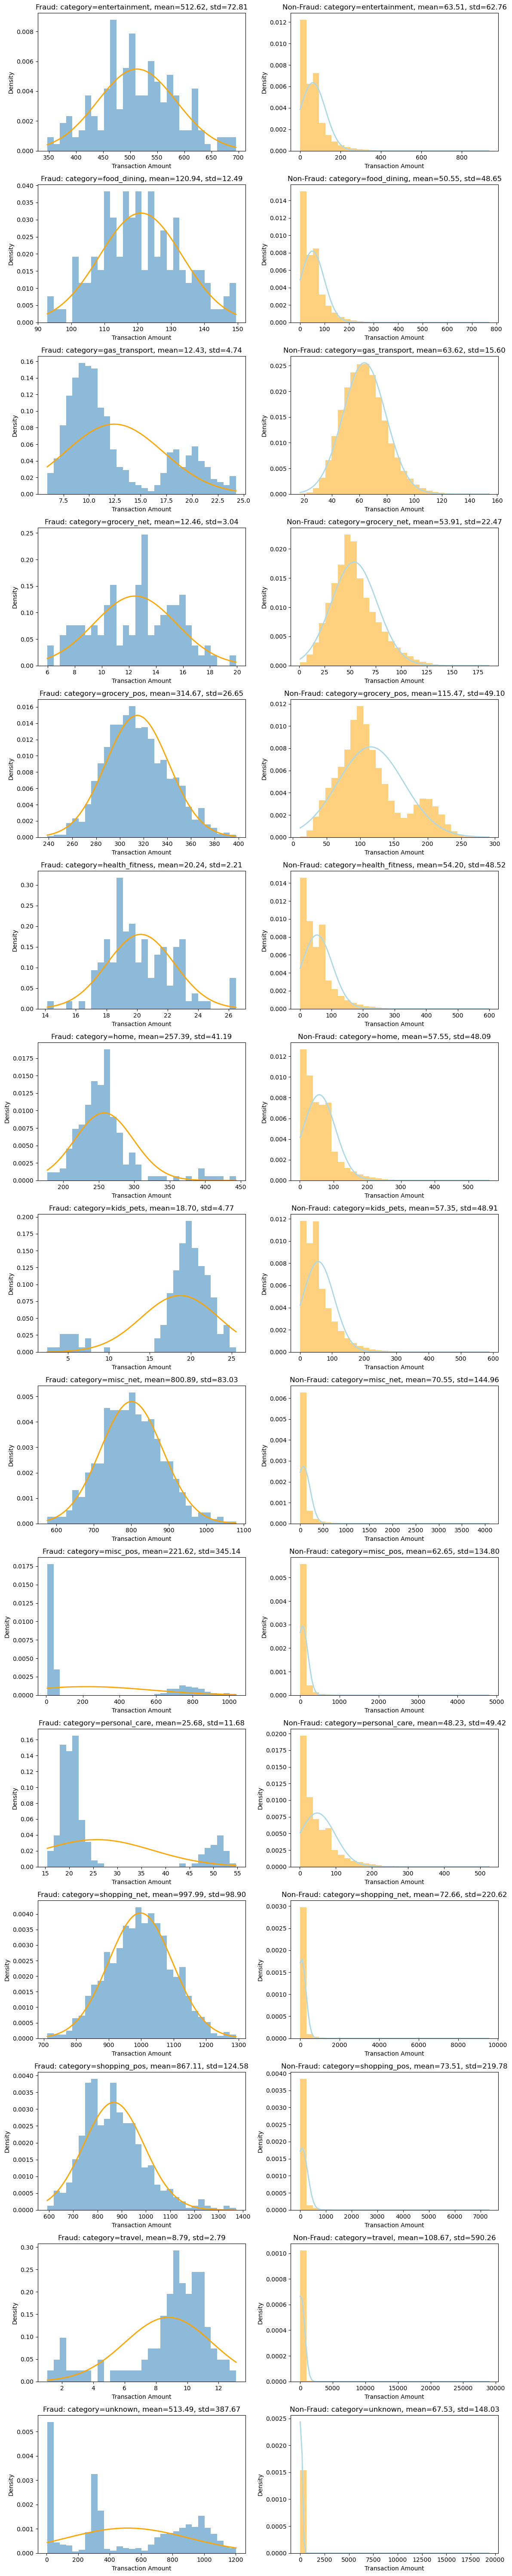

In [13]:
# Group data by category and fraud label
categories = df['category'].unique()

# Sort categories alphabetically
categories = sorted(categories)

# Create figure with subplots
# One row per category, two columns (Fraud, Non-Fraud)
n_cats = len(categories)
fig, axes = plt.subplots(nrows=n_cats, ncols=2, figsize=(12, 4 * n_cats), sharex=False)

if n_cats == 1:
    axes = np.array([axes])

for i, cat in enumerate(categories):
    # Subset data for this category
    cat_data_fraud = df[(df['category'] == cat) & (df['is_fraud'] == 1)]['amt']
    cat_data_non_fraud = df[(df['category'] == cat) & (df['is_fraud'] == 0)]['amt']

    # Fraudulent subplot
    ax_fraud = axes[i, 0]
    if len(cat_data_fraud) > 0:
        mean_fraud = cat_data_fraud.mean()
        std_fraud = cat_data_fraud.std()

        # Plot histogram
        ax_fraud.hist(cat_data_fraud, bins=30, alpha=0.5, density=True)

        # Generate x-values PDF
        x_vals = np.linspace(cat_data_fraud.min(), cat_data_fraud.max(), 100)

        # Calculate normal PDF
        pdf_fraud = norm.pdf(x_vals, mean_fraud, std_fraud) if std_fraud > 0 else None

        # Overlay PDF
        if pdf_fraud is not None:
            ax_fraud.plot(x_vals, pdf_fraud, color='orange', linewidth=2)

        # Title shows category and stats
        ax_fraud.set_title(f'Fraud: category={cat}, mean={mean_fraud:.2f}, std={std_fraud:.2f}')
        ax_fraud.set_xlabel('Transaction Amount')
        ax_fraud.set_ylabel('Density')
    else:
        ax_fraud.set_title(f'Fraud: category={cat} (No Data)')
        ax_fraud.set_xlabel('Transaction Amount')
        ax_fraud.set_ylabel('Density')

    # Non-Fraudulent subplot
    ax_non_fraud = axes[i, 1]
    if len(cat_data_non_fraud) > 0:
        mean_non_fraud = cat_data_non_fraud.mean()
        std_non_fraud = cat_data_non_fraud.std()

        ax_non_fraud.hist(cat_data_non_fraud, bins=30, alpha=0.5, density=True, color='orange')

        x_vals = np.linspace(cat_data_non_fraud.min(), cat_data_non_fraud.max(), 100)
        pdf_non_fraud = norm.pdf(x_vals, mean_non_fraud, std_non_fraud) if std_non_fraud > 0 else None

        if pdf_non_fraud is not None:
            ax_non_fraud.plot(x_vals, pdf_non_fraud, color='lightblue', linewidth=2)

        ax_non_fraud.set_title(f'Non-Fraud: category={cat}, mean={mean_non_fraud:.2f}, std={std_non_fraud:.2f}')
        ax_non_fraud.set_xlabel('Transaction Amount')
        ax_non_fraud.set_ylabel('Density')
    else:
        ax_non_fraud.set_title(f'Non-Fraud: category={cat} (No Data)')
        ax_non_fraud.set_xlabel('Transaction Amount')
        ax_non_fraud.set_ylabel('Density')

plt.tight_layout()
plt.show()

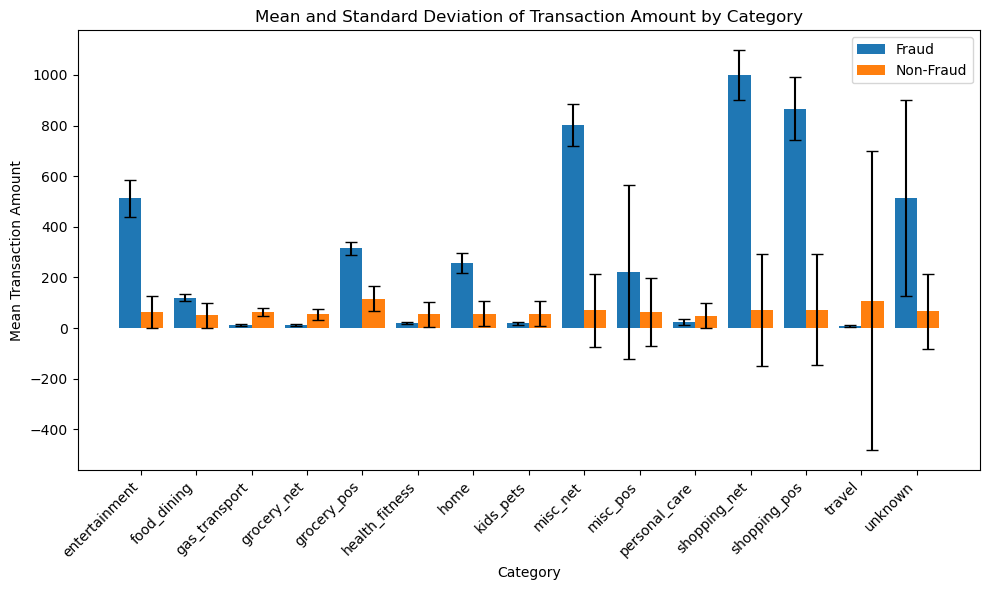

In [14]:

# Group by category is_fraud, get mean & std
stats = df.groupby(['category', 'is_fraud'])['amt'].agg(['mean', 'std']).reset_index()

# Sort by category
stats = stats.sort_values(by='category')

# Pivot Fraud vs. Non-Fraud
pivoted = stats.pivot(index='category', columns='is_fraud', values=['mean', 'std'])

# The pivoted DataFrame will have a multi-level column index
pivoted.columns = ['mean_non_fraud', 'mean_fraud', 'std_non_fraud', 'std_fraud']

categories = pivoted.index
x = np.arange(len(categories))  # the label locations
bar_width = 0.4

fig, ax = plt.subplots(figsize=(10, 6))

# Fraud bars
ax.bar(x - bar_width/2, pivoted['mean_fraud'], bar_width, yerr=pivoted['std_fraud'], label='Fraud', capsize=4)

# Non-Fraud bars
ax.bar(x + bar_width/2, pivoted['mean_non_fraud'], bar_width, yerr=pivoted['std_non_fraud'], label='Non-Fraud', capsize=4)


ax.set_title('Mean and Standard Deviation of Transaction Amount by Category')
ax.set_xlabel('Category')
ax.set_ylabel('Mean Transaction Amount')
ax.set_xticks(x)
ax.set_xticklabels(categories, rotation=45, ha='right')
ax.legend()

plt.tight_layout()
plt.show()